### Build Your First CNN with Keras

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense
)
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

tf.keras.utils.set_random_seed(42)

### Load and Preprocess MNIST

In [2]:
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

# Normalize pixels from [0, 255] to [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add the channel dimension: (height, width, channels)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (60000, 28, 28, 1)
Testing data: (10000, 28, 28, 1)


### Visualize sample images

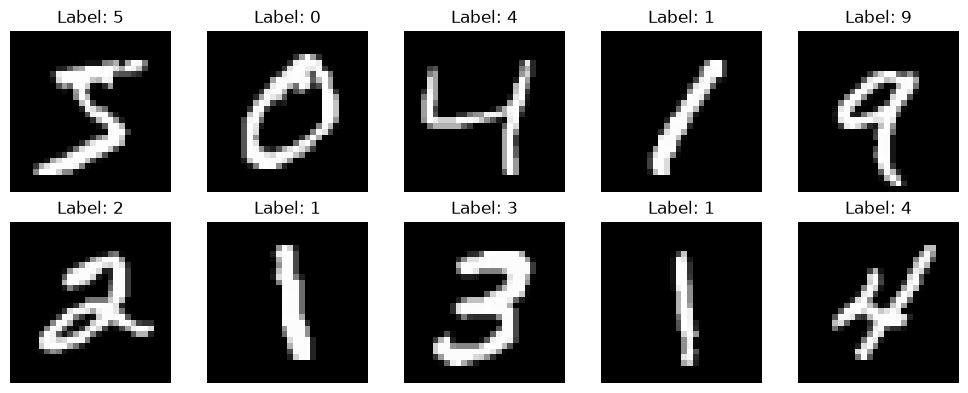

In [3]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i, :, :, 0], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Build CNN

In [4]:
model = Sequential([
    Input(shape=(28, 28, 1)),

    # Feature extraction
    Conv2D(32, kernel_size=3, activation="relu"),
    MaxPooling2D(pool_size=2),

    Conv2D(64, kernel_size=3, activation="relu"),
    MaxPooling2D(pool_size=2),

    # Classification
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

### Train Model

In [5]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 55s 119ms/step - accuracy: 0.9279 - loss: 0.2489 - val_accuracy: 0.9812 - val_loss: 0.0643
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 50s 119ms/step - accuracy: 0.9794 - loss: 0.0677 - val_accuracy: 0.9872 - val_loss: 0.0486
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 103ms/step - accuracy: 0.9848 - loss: 0.0478 - val_accuracy: 0.9873 - val_loss: 0.0415
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.9884 - loss: 0.0365 - val_accuracy: 0.9890 - val_loss: 0.0385
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - accuracy: 0.9910 - loss: 0.0290 - val_accuracy: 0.9893 - val_loss: 0.0362
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.9926 - loss: 0.0240 - val_accuracy: 0.9890 - val_loss: 0.0413
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - accuracy: 0.9941 - loss: 0.0193 - val_accuracy: 0.9890 - val_loss: 0.0438


### Training curves

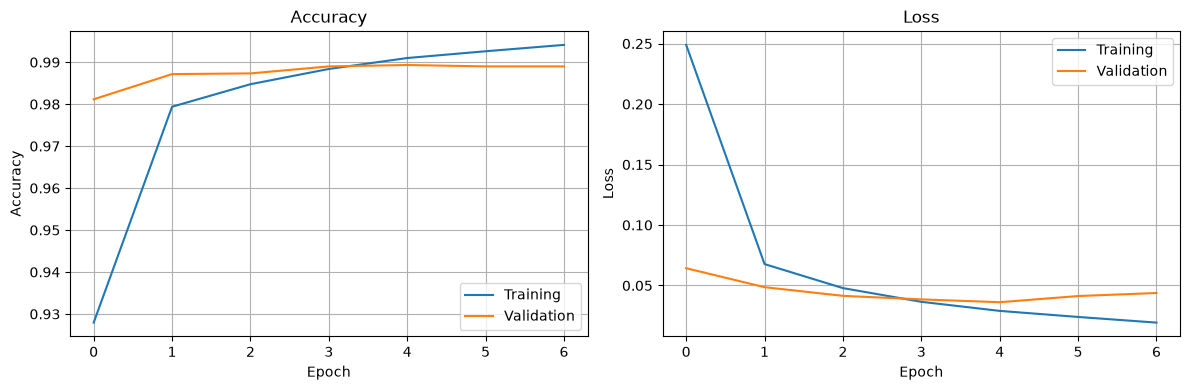

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

### Evaluate

In [7]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")

Test loss: 0.0327
Test accuracy: 98.9500%


### Confusion Matrix

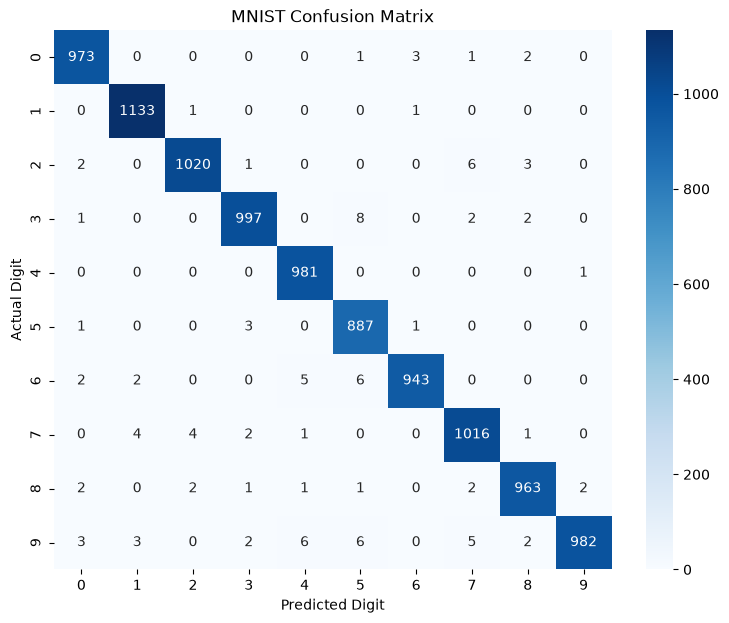

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.98      0.99      0.99       892
           6       0.99      0.98      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       1.00      0.97      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [8]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("MNIST Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.show()

print(classification_report(y_test, y_pred))

### Visualize predictions

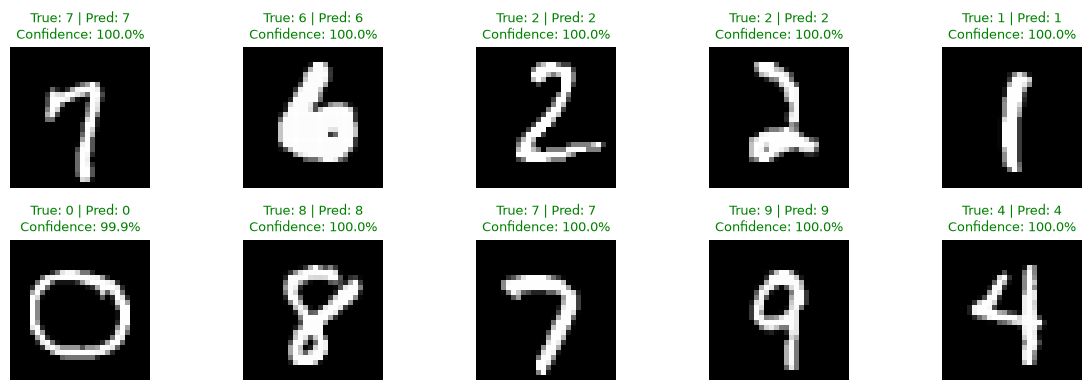

In [9]:
indices = np.random.default_rng(42).choice(
    len(X_test), size=10, replace=False
)

plt.figure(figsize=(12, 4))

for i, idx in enumerate(indices):
    prediction = y_pred[idx]
    actual = y_test[idx]
    confidence = y_prob[idx, prediction]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx, :, :, 0], cmap="gray")
    plt.title(
        f"True: {actual} | Pred: {prediction}\n"
        f"Confidence: {confidence:.1%}",
        color="green" if prediction == actual else "red",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### Learned Feature maps

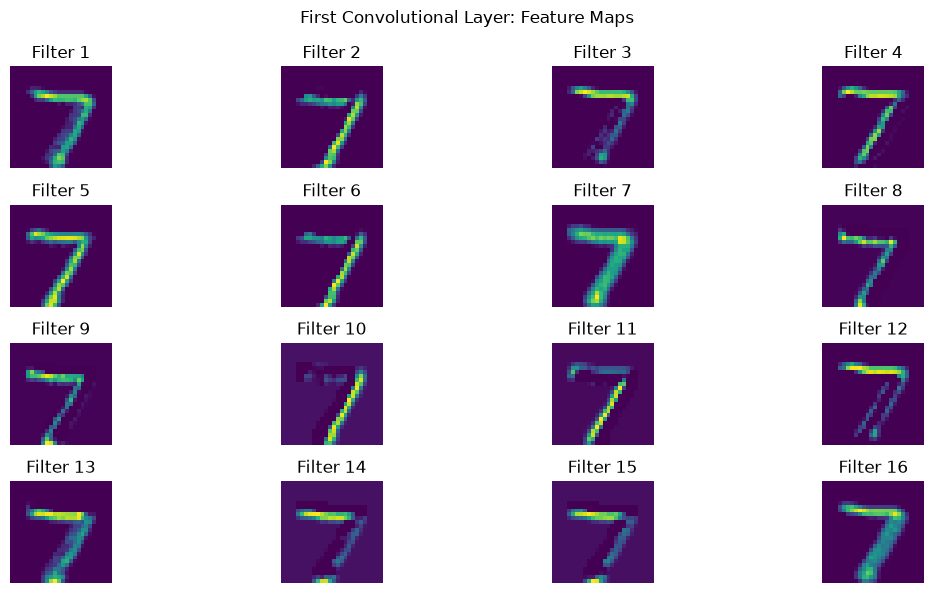

In [10]:
conv_layer = model.layers[0]

feature_extractor = tf.keras.Model(
    inputs=model.inputs,
    outputs=conv_layer.output
)

sample = X_test[0:1]
feature_maps = feature_extractor.predict(sample, verbose=0)

plt.figure(figsize=(12, 6))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")
    plt.title(f"Filter {i + 1}")
    plt.axis("off")

plt.suptitle("First Convolutional Layer: Feature Maps")
plt.tight_layout()
plt.show()